# Podstawy AI – Sterownik wentylatora w języku FCL

**FCL** (*Fuzzy Control Language*, norma IEC 61131-7) to standardowy, tekstowy format opisu sterowników rozmytych, używany w przemyśle. Plik FCL zawiera wszystko, co sterownik wie: zmienne, funkcje przynależności, reguły i ustawienia operatorów.

**Potrzebne pliki** (w tym samym folderze co notebook; w Google Colab: ikona folderu po lewej → „Prześlij”):
- `wentylator.fcl` – sterownik do analizy,
- `fcl_narzedzie.py` – narzędzie, które czyta pliki FCL i liczy wynik.

Nic nie trzeba instalować – narzędzie używa tylko `numpy` i `matplotlib`, które są w Colab.

**Plan:**
1. Analiza pliku FCL (A–C)
2. Dodanie stanu `very_hot` i nowej reguły
3. Testy sterownika
4. Trzy konfiguracje: implikacja, wyostrzanie, suma zbiorów
5. Ocena sterownika
6. Drugie wejście: wilgotność

**Do oddania:** pliki FCL (co najmniej 3 konfiguracje i wersja z wilgotnością) oraz ten notebook zapisany jako PDF (Plik → Drukuj → Zapisz jako PDF).

In [1]:
from fcl_narzedzie import wynik, tabela, rysuj_zbiory, krzywa, wariant, rozszerz, krzywe
print(open("wentylator.fcl", encoding="utf-8").read())

(* Podstawy AI – sterownik rozmyty wentylatora
   Jedno wejście: temperatura, jedno wyjście: prędkość wentylatora. *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skalu

---
## 1. Analiza pliku FCL

Plik składa się z bloków. Każdy odpowiada jednemu krokowi sterownika rozmytego:

| blok | co zawiera |
|---|---|
| `VAR_INPUT` / `VAR_OUTPUT` | nazwy wejść i wyjść |
| `FUZZIFY` | funkcje przynależności wejścia, zapisane punktami `(x, μ)` – łamana przez te punkty |
| `DEFUZZIFY` | funkcje przynależności wyjścia, metoda wyostrzania `METHOD`, wartość `DEFAULT` |
| `RULEBLOCK` | operatory (`AND`, `ACT` – implikacja, `ACCU` – suma zbiorów) i reguły `IF … THEN …` |

Przykład: `TERM cold := (0, 1) (10, 1) (20, 0);` znaczy: do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C.

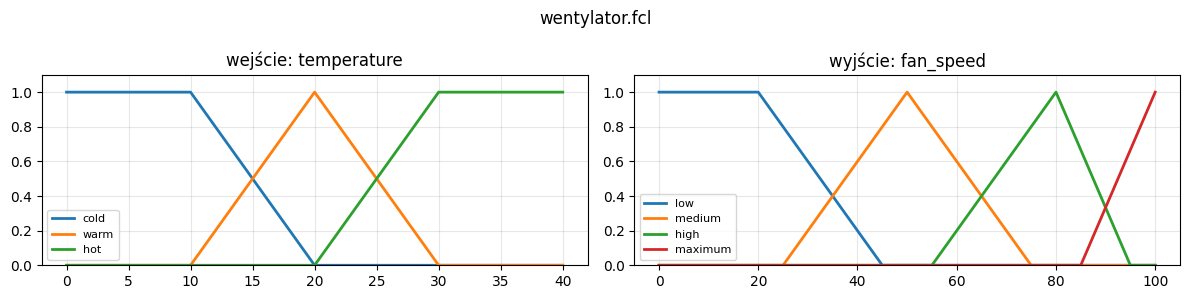

In [2]:
rysuj_zbiory("wentylator.fcl")

**Zadanie 1A.** Wypisz zmienne wejściowe i wyjściowe (nazwa, zakres, jednostka).

**Zadanie 1B.** Wypisz funkcje przynależności każdej zmiennej i opisz słowami, co znaczą (np. „cold – do 10 °C na pewno zimno, od 20 °C na pewno nie”).

**Zadanie 1C.** Wypisz reguły i opisz jednym zdaniem, jak działa ten sterownik.



**Zadanie 1A.**
Zmienne wejściowe to temperatura - cold, warm, hot podawane w stopniach Celsjusza. Na wyjściu natomiast mamy prędkość wiatraka - low, medium, high, maximum.

**Zadanie 1B.**

cold - zimno do 10 stopni, im więcej tym mniej zimno

warm - ciepło od 10 stopni, na pewno ciepło przy 20 stopniach i coraz mniej
ciepło do 30 stopni.

hot - może ciepło od 20 stopni, na pewno ciepło od 30 stopni w górę.

**Zadanie 1C.**

RULE 1 : IF temperature IS cold THEN fan_speed IS low;

Jeśli zimno to wiatrak wolno.

RULE 2 : IF temperature IS warm THEN fan_speed IS medium;

Jeśli ciepło to wiatrak działa normalnie.

RULE 3 : IF temperature IS hot  THEN fan_speed IS high;

Jeśli gorąco to wiatrak bardzo szybko.

---
## 2. Dodanie stanu `very_hot`

Komórka poniżej zapisuje plik `wentylator_k1.fcl`. Na start zawiera kopię oryginału. Zmień go bezpośrednio w komórce:

1. **(A)** Dodaj do `temperature` stan `very_hot`. Pamiętaj, że `hot` i `very_hot` muszą się **nakładać**, a `hot` powinien przestać być płaski do 40 °C (inaczej przy 40 °C będzie jednocześnie w pełni „hot” i „very_hot”).
2. **(B)** Dodaj regułę: jeśli `very_hot`, to `fan_speed` = `maximum`.

Uruchom komórkę – zapisze plik. Potem uruchom następną, żeby zobaczyć wykres.

In [25]:
%%writefile wentylator_k1.fcl
(* TODO: dodaj stan very_hot i regułę dla niego *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (25, 1) (30,0);
    TERM very_hot := (25,0) (30,1) (40,1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skaluje *)
    ACCU : MAX;             (* suma zbiorów na wyjściu: MAX, BSUM *)

    RULE 1 : IF temperature IS cold THEN fan_speed IS low;
    RULE 2 : IF temperature IS warm THEN fan_speed IS medium;
    RULE 3 : IF temperature IS hot  THEN fan_speed IS high;
    RULE 4 : IF temperature IS very_hot THEN fan_speed IS maximum;
END_RULEBLOCK

END_FUNCTION_BLOCK

Overwriting wentylator_k1.fcl


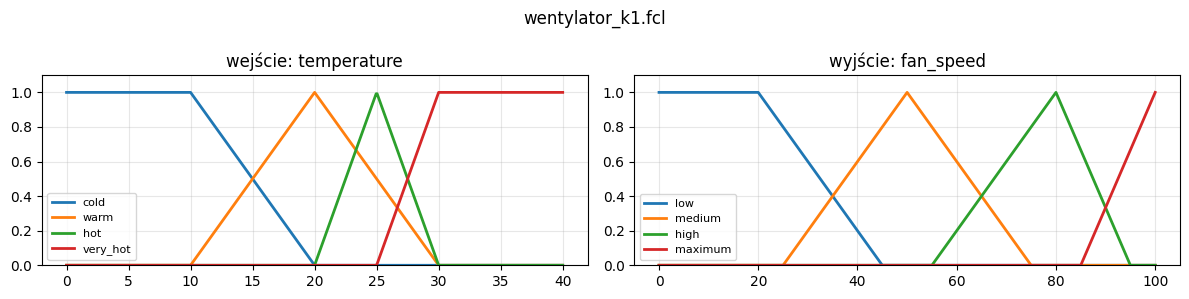

In [26]:
rysuj_zbiory("wentylator_k1.fcl")

---
## 3. Testy sterownika

**Zadanie 2C.** Porównaj oryginał i Twoją wersję dla temperatur od 0 do 40 °C co 5 stopni. Wykres pokazuje prędkość dla wszystkich temperatur naraz.

 temperature  wentylator  wentylator_k1
           0       17.03          17.03
           5       17.03          17.03
          10       17.03          17.03
          15       34.44          34.44
          20       50.00          50.00
          25       61.15          63.62
          30       76.67          95.03
          35       76.67          95.03
          40       76.67          95.03


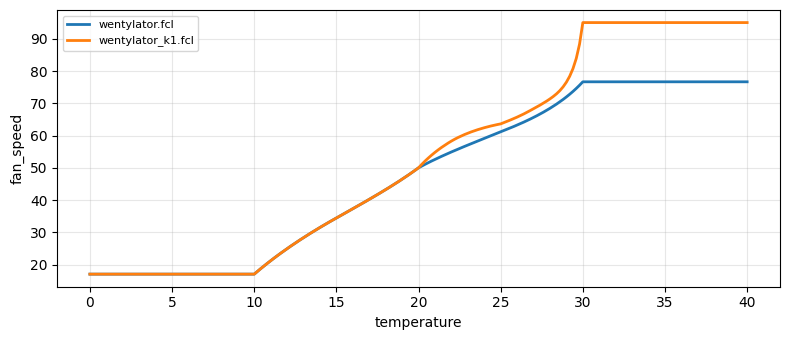

In [27]:
TEMPERATURY = [0, 5, 10, 15, 20, 25, 30, 35, 40]
tabela(["wentylator.fcl", "wentylator_k1.fcl"], "temperature", TEMPERATURY)
krzywa(["wentylator.fcl", "wentylator_k1.fcl"], "temperature")

**Pytanie 3a.** Co robi oryginalny sterownik powyżej 30 °C? Co zmieniło dodanie `very_hot`?

**Pytanie 3b.** Jaką prędkość daje sterownik przy 0 °C, a jaką przy 40 °C? Czy wentylator kiedykolwiek się wyłącza albo osiąga 100%? Dlaczego?

**Zadanie 2C.**

Po zaimplementowaniu temperatury very_hot widać, że wiatrak dla dużych temperatur znacząco zwiększa swoją moc działania np. dla 30 stopni mamy 76% oraz 95% kolejno dla oryginały i po w prowadzeniu very_hot. Dla małych wartości temperatury działa tak jak w oryginale.

**Zadanie 3a.**

**Zadanie 3b.**

Przy 0 stopniach mamy wartości mocy w granicach 15%-17%. Natomiast dla wartości 40 stopni mamy po wprowadzeniu very_hot aż 95% procent. Więc widać, że wiatrak nie osiąga 0% ani 100% cały czas działa ale nigdy na maksymalnych obrotach.


---
## 4. Trzy konfiguracje

**Zadanie 3A.** Przetestuj sterownik z innymi ustawieniami. Każda konfiguracja to osobny plik FCL, w którym zmieniasz **jedną** rzecz:

| ustawienie w FCL | co określa | wariant do sprawdzenia |
|---|---|---|
| `ACT` | implikacja: jak siła reguły zmienia jej wniosek | `PROD` zamiast `MIN` |
| `METHOD` | wyostrzanie: jak z kształtu zrobić jedną liczbę | `MM` (środek maksimum) zamiast `COG` |
| `ACCU` | suma zbiorów na wyjściu: jak łączyć wnioski reguł | `BSUM` (suma ograniczona) zamiast `MAX` |

Funkcja `wariant` tworzy kopię pliku ze zmienionym ustawieniem. Możesz też skopiować plik ręcznie i zmienić jedną linijkę.

Zapisano wentylator_k2.fcl: ACT = PROD
Zapisano wentylator_k3.fcl: METHOD = MM
Zapisano wentylator_k4.fcl: ACCU = BSUM
 temperature  wentylator_k1  wentylator_k2  wentylator_k3  wentylator_k4
           0          17.03          17.03          10.00          17.03
           5          17.03          17.03          10.00          17.03
          10          17.03          17.03          10.00          17.03
          15          34.44          31.08          30.93          34.50
          20          50.00          50.00          50.00          50.00
          25          63.62          66.64          80.00          63.76
          30          95.03          95.03         100.00          95.03
          35          95.03          95.03         100.00          95.03
          40          95.03          95.03         100.00          95.03
          28          71.37          73.67          97.00          71.80
          32          95.03          95.03         100.00          95.03
     

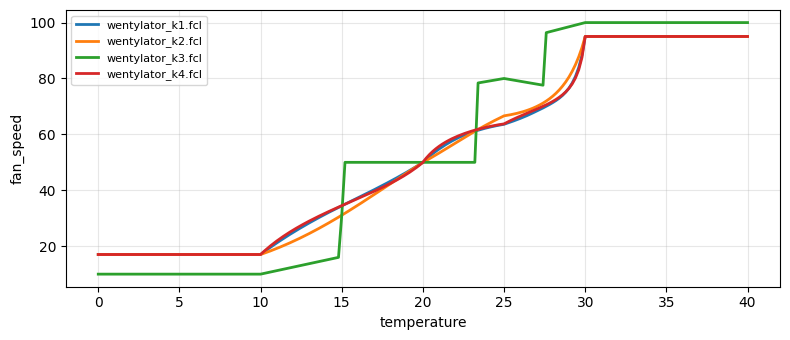

In [33]:
# TODO: utwórz trzy konfiguracje (po jednej zmianie każda)
k2 = wariant("wentylator_k1.fcl", "wentylator_k2.fcl", ACT="PROD")
k3 = wariant("wentylator_k1.fcl", "wentylator_k3.fcl", METHOD ="MM")
k4 = wariant("wentylator_k1.fcl","wentylator_k4.fcl", ACCU = "BSUM")

KONFIGURACJE = ["wentylator_k1.fcl", k2, k3, k4]   # TODO: dopisz k3 i k4
tabela(KONFIGURACJE, "temperature", TEMPERATURY + [28, 32, 34])
krzywa(KONFIGURACJE, "temperature")

**Zadanie 3A (opis).** Dla każdej konfiguracji opisz: co zmieniłeś, przy jakich temperaturach wynik się zmienił i o ile. Która zmiana ma największy wpływ?

Największy wpływ ewidentinie ma podejście MM czyli środek maksimum widać, że wzrost nie jest łagodny lecz ma pewne skoki. Ta metoda drastycznie zmienia prędkość wiatraka przy małych zmianach temepratury takich jak 1 stopień.
Pozostałe metody są bardzo zbliżone do oryginalnego sterownika.

---
## 5. Ocena sterownika

**Zadanie 3B.** Jak oceniasz działanie sterownika? Odnieś się do:
- czy prędkość rośnie z temperaturą płynnie, czy skokami,
- czy zakres prędkości (najmniejsza i największa) jest sensowny dla wentylatora,
- którą konfigurację wybrałbyś do prawdziwego urządzenia i dlaczego.

Sterownik w większości przypadków prędkość rośnei płynnie wraz ze wzrostem temperatury. Mamy jeden przypadek w którym są widoczne skoki.

Jak najbardziej najmniejsze wartości prędkości jakie możemy uzyskać to około 10%
natomiast największe to w granicach 95%-100%. Jest to realne odzwierciedlenie.

Ja wybrałbym kofigurację PROD, która najwierniej oddaje wzrost prędkości do wzrostu temperatury.

---
## 6. Drugie wejście: wilgotność

Przy wysokiej wilgotności to samo ciepło jest bardziej uciążliwe, więc wentylator powinien kręcić się szybciej. Dodajemy do Twojego sterownika z części 2 drugie wejście `humidity` (wilgotność powietrza, 0–100%).

### 6.1 Rozszerzenie pliku

Nie musisz przepisywać całego pliku. Funkcja `rozszerz` bierze `wentylator_k1.fcl` i wkleja we właściwe miejsca trzy fragmenty, które piszesz w FCL:
1. nowe wejście w `VAR_INPUT` (gotowe),
2. blok `FUZZIFY humidity` z trzema stanami: `dry`, `normal`, `humid`,
3. co najmniej dwie nowe reguły, np. „ciepło **i** wilgotno → szybko”, „gorąco **i** wilgotno → maksimum”.

Zapisano wentylator_h.fcl – plik wczytuje się poprawnie.


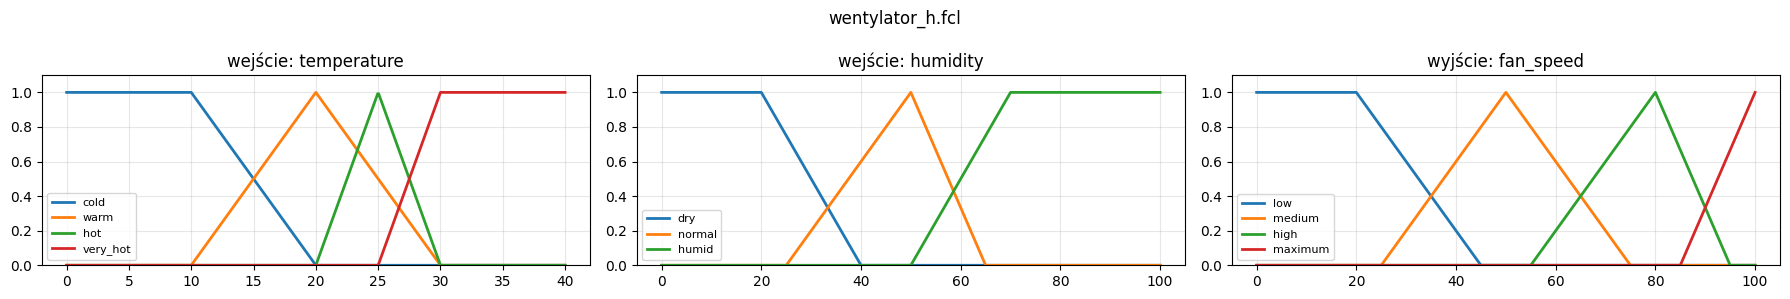

In [47]:
NOWE_WEJSCIE = "humidity : REAL;     (* wilgotność [%] *)"

# TODO: uzupełnij punkty (x, μ) – sąsiednie stany muszą się nakładać
NOWY_FUZZIFY = """
FUZZIFY humidity
    RANGE := (0 .. 100);
    TERM dry    := (0, 1) (20, 1) (40, 0);
    TERM normal := (25,0) (50,1) (65,0);
    TERM humid  := (50,0) (70,1) (100,1);
END_FUZZIFY"""


# TODO: dopisz co najmniej dwie reguły z humidity (numeruj dalej: RULE 5, RULE 6, ...)
NOWE_REGULY = """
RULE 5 : IF temperature IS hot AND humidity IS humid THEN fan_speed IS maximum;
RULE 6 : IF temperature IS very_hot AND humidity IS humid THEN fan_speed IS maximum;
RULE 7 : IF temperature IS warm AND humidity IS humid THEN fan_speed IS high;
RULE 8 : IF temperature IS cold AND humidity IS dry THEN fan_speed IS low;
RULE 9 : IF temperature IS warm AND humidity IS dry THEN fan_speed IS medium;
"""

rozszerz("wentylator_k1.fcl", "wentylator_h.fcl",
         wejscie=NOWE_WEJSCIE, fuzzify=NOWY_FUZZIFY, reguly=NOWE_REGULY)
rysuj_zbiory("wentylator_h.fcl")

**Testy.** Ta sama temperatura przy suchym (20%) i wilgotnym (90%) powietrzu, a potem wilgotność od 0 do 100% przy stałych 25 °C.

Powietrze suche (humidity = 20):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         34.44
          20         50.00
          25         63.62
          30         95.03
          35         95.03
          40         95.03

Powietrze wilgotne (humidity = 90):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         45.58
          20         61.54
          25         68.38
          30         95.03
          35         95.03
          40         95.03

Stała temperatura 25 °C:
    humidity  wentylator_h
           0         63.62
          20         63.62
          40         63.62
          60         66.95
          75         68.38
          90         68.38
         100         68.38


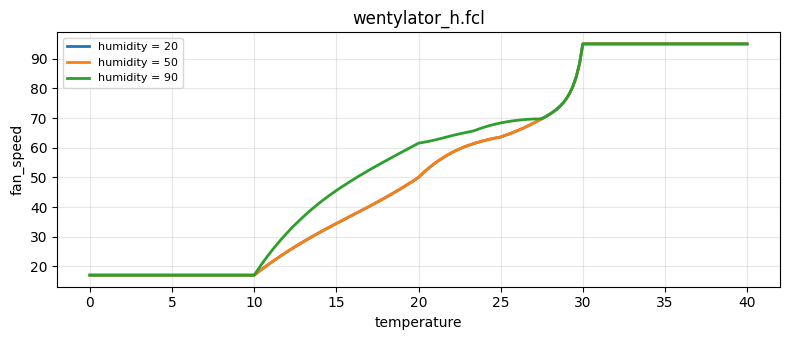

In [48]:
print("Powietrze suche (humidity = 20):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=20)
print("\nPowietrze wilgotne (humidity = 90):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=90)
print("\nStała temperatura 25 °C:")
tabela("wentylator_h.fcl", "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6a.** O ile wilgotne powietrze zwiększa prędkość przy 25 °C? Czy to dużo, czy mało?

**Pytanie 6b.** Czy wilgotność cokolwiek zmienia przy 10 °C? Dlaczego?

**Pytanie 6c.** Reguła 2 („warm → medium”) nic nie wie o wilgotności. Co robi, gdy powietrze jest wilgotne? Jak to wpływa na wynik z pytania 6a?

6a -  Dla temperatury 25 stopni wilgotność zwiększa prędkość wiatraka o 5% co
wydaje się być bardzo znikomą wartością.

6b - Przy 10 stopniach wilgotnośc nie wpływa na prędkość. Wynika to z tego że
jest to tak mała temperatura, że zawsze wiatrak będzie chodził w tym zakresie.

6c - Reguła 2 całkowicie ignoruje wilgotność, przez co aktywuje się w dokładnie takim samym stopniu dla suchego, jak i wilgotnego powietrza. Prędkość wentylatora pozostaje całkowicie niezmienna (stałe 63.62%) niezależnie od poziomu wilgotności.

### 6.2 Poprawka: stare reguły tylko dla niewilgotnego powietrza

Zmień reguły 2 i 3 tak, żeby działały tylko, gdy powietrze **nie** jest wilgotne. FCL ma do tego słowo `NOT`:

`RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;`

Komórka poniżej robi kopię pliku i zamienia w niej tekst reguł.

Stała temperatura 25 °C:
    humidity  wentylator_h  wentylator_h2
           0         63.62          63.62
          20         63.62          63.62
          40         63.62          63.62
          60         66.95          65.26
          75         68.38          81.84
          90         68.38          81.84
         100         68.38          81.84


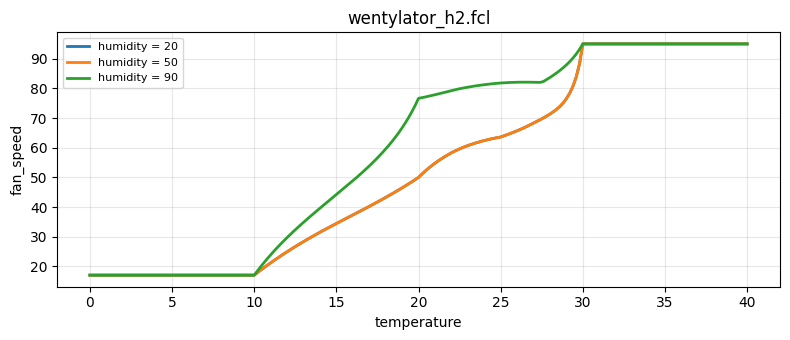

In [50]:
tekst = open("wentylator_h.fcl", encoding="utf-8").read()
# TODO: zamień reguły 2 i 3 (tekst przed zamianą musi być DOKŁADNIE taki jak w Twoim pliku)
tekst = tekst.replace("RULE 2 : IF temperature IS warm THEN fan_speed IS medium;",
                      "RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;")
tekst = tekst.replace("RULE 3 : IF temperature IS hot  THEN fan_speed IS high;",
                      "RULE 3 : IF temperature IS hot AND humidity IS NOT humid THEN fan_speed IS high;")
open("wentylator_h2.fcl", "w", encoding="utf-8").write(tekst)

print("Stała temperatura 25 °C:")
tabela(["wentylator_h.fcl", "wentylator_h2.fcl"], "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h2.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6d.** Jak zmienił się wynik przy 25 °C i wilgotności 90% po poprawce? Dlaczego?

**Pytanie 6e.** Pełna baza reguł dla 4 stanów temperatury i 3 stanów wilgotności ma 4 × 3 = 12 reguł. Ile reguł ma Twój sterownik? Czy przy dwóch wejściach logika rozmyta daje coś, czego nie dałaby zwykła funkcja temperatury?

6d - Przy tych wartościach widać teraz, że wiatrak działa dużo szybciej, z 68%
przeszliśmy na blisko 82%.

6e - Mój sterownik ma 6 reguł, 4 dla temperatury oraz 2 dla wilgotności.
Tak. Przy dwóch wejściach logika rozmyta pozwala na łatwe modelowanie nieliniowych interakcji między zmiennymi za pomocą prostych reguł słowych.



---
## Do oddania

1. Pliki FCL: `wentylator_k1.fcl` (z `very_hot`) oraz co najmniej dwa warianty (`wentylator_k2.fcl`, `wentylator_k3.fcl`, …). W Colab: kliknij plik w panelu po lewej → „Pobierz”.
2. Pliki z wilgotnością: `wentylator_h.fcl` i `wentylator_h2.fcl`.
3. Ten notebook z wynikami i odpowiedziami zapisany jako PDF: Plik → Drukuj → Zapisz jako PDF.